Using latest CSV: C:\Users\GH22208\Dev\data-trends\data\google_trends\lifestyle_2026-01-18.csv


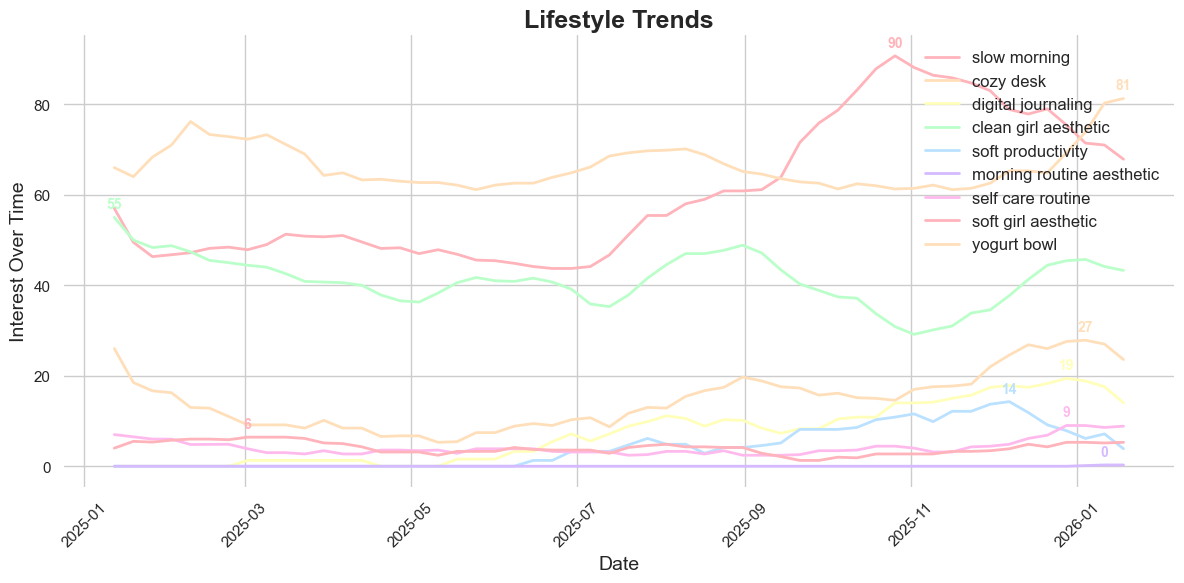

🎨 Combined chart saved to plots\combined_trends_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\slow_morning_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\cozy_desk_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\digital_journaling_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\clean_girl_aesthetic_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\soft_productivity_lifestyle_2026-01-18.png


C:\Users\GH22208\AppData\Local\Temp\ipykernel_22104\4117255809.py:91: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


✅ Saved individual chart: plots\morning_routine_aesthetic_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\self_care_routine_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\soft_girl_aesthetic_lifestyle_2026-01-18.png
✅ Saved individual chart: plots\yogurt_bowl_lifestyle_2026-01-18.png


In [1]:
# -------------------------------
# 1️⃣ IMPORT LIBRARIES
# -------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import glob
import os

# -------------------------------
# 2️⃣ CONFIGURATION
# -------------------------------
TRENDS_DIR = Path(r"C:/Users/GH22208/Dev/data-trends/data/google_trends")
OUTPUT_DIR = Path("plots")
ROLLING_WINDOW = 7  # smoothing
PASTEL_COLORS = ["#FFB3BA", "#FFDFBA", "#FFFFBA", "#BAFFC9", "#BAE1FF", "#D5BAFF", "#FFBAED"]

# Ensure output directory exists
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Seaborn style for soft aesthetic
sns.set(style="whitegrid")

# -------------------------------
# 3️⃣ AUTOMATICALLY FIND LATEST CSV
# -------------------------------
all_csvs = sorted(TRENDS_DIR.glob("*.csv"))
if not all_csvs:
    raise FileNotFoundError(f"No CSV files found in {TRENDS_DIR}")
latest_csv = all_csvs[-1]  # newest file based on filename
print(f"Using latest CSV: {latest_csv}")

# -------------------------------
# 4️⃣ LOAD DATA
# -------------------------------
df = pd.read_csv(latest_csv, index_col=0, parse_dates=True)

# Optional: drop 'isPartial' column if exists
if "isPartial" in df.columns:
    df = df.drop(columns=["isPartial"])

# -------------------------------
# 5️⃣ SMOOTH DATA
# -------------------------------
df_smooth = df.rolling(window=ROLLING_WINDOW, min_periods=1).mean()

# -------------------------------
# 6️⃣ PLOT COMBINED TRENDS
# -------------------------------
plt.figure(figsize=(12, 6))
for i, column in enumerate(df_smooth.columns):
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], label=column, color=color, linewidth=2)

    # Annotate highest point for each trend
    max_val = df_smooth[column].max()
    max_date = df_smooth[column].idxmax()
    plt.text(max_date, max_val + 2, f"{int(max_val)}", color=color, fontsize=10, fontweight='bold', ha='center')

plt.title("Lifestyle Trends", fontsize=18, weight='bold')
plt.xlabel("Date", fontsize=14)
plt.ylabel("Interest Over Time", fontsize=14)
plt.xticks(rotation=45)
plt.legend(frameon=False, fontsize=12)
sns.despine(left=True, bottom=True)

# Save combined chart
combined_file = OUTPUT_DIR / f"combined_trends_{latest_csv.stem}.png"
plt.tight_layout()
plt.savefig(combined_file, dpi=300)
plt.show()
print(f"🎨 Combined chart saved to {combined_file}")

# -------------------------------
# 7️⃣ OPTIONAL: EXPORT INDIVIDUAL TREND CHARTS
# -------------------------------
for i, column in enumerate(df_smooth.columns):
    plt.figure(figsize=(8, 4))
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], color=color, linewidth=2)

    # Annotate peak
    max_val = df_smooth[column].max()
    max_date = df_smooth[column].idxmax()
    plt.text(max_date, max_val + 2, f"{int(max_val)}", color=color, fontsize=10, fontweight='bold', ha='center')

    plt.title(column, fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()

    file_path = OUTPUT_DIR / f"{column.replace(' ', '_')}_{latest_csv.stem}.png"
    plt.savefig(file_path, dpi=300)
    plt.close()
    print(f"✅ Saved individual chart: {file_path}")


In [ ]:
# -------------------------------
# 1️⃣ IMPORT LIBRARIES
# -------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# -------------------------------
# 2️⃣ CONFIGURATION
# -------------------------------
DATA_FILE = r"C:/Users/GH22208/Dev/data-trends/data/google_trends/lifestyle_2026-01-18.csv"  # change to your latest CSV
OUTPUT_DIR = "plots"
ROLLING_WINDOW = 7  # smooth trends (7-day rolling average)

# Ensure output directory exists
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Set seaborn style for Pinterest / soft aesthetic
sns.set(style="whitegrid")
PASTEL_COLORS = ["#FFB3BA", "#FFDFBA", "#FFFFBA", "#BAFFC9", "#BAE1FF", "#D5BAFF", "#FFBAED"]

# -------------------------------
# 3️⃣ LOAD DATA
# -------------------------------
df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)
df.head()

# -------------------------------
# 4️⃣ SMOOTH DATA
# -------------------------------
df_smooth = df.rolling(window=ROLLING_WINDOW, min_periods=1).mean()

# -------------------------------
# 5️⃣ PLOT TRENDS
# -------------------------------
plt.figure(figsize=(12, 6))

for i, column in enumerate(df_smooth.columns):
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], label=column, color=color, linewidth=2)

plt.title("Lifestyle Search Trends", fontsize=18, weight='bold')
plt.xlabel("Date", fontsize=14)
plt.ylabel("Interest Over Time", fontsize=14)
plt.xticks(rotation=45)
plt.legend(frameon=False, fontsize=12)
sns.despine(left=True, bottom=True)

# Save figure
output_file = f"{OUTPUT_DIR}/lifestyle_trends.png"
plt.tight_layout()
plt.savefig(output_file, dpi=300)
plt.show()
print(f"🎨 Saved chart to {output_file}")

# -------------------------------
# 6️⃣ OPTIONAL: EXPORT INDIVIDUAL CHARTS
# -------------------------------
for i, column in enumerate(df_smooth.columns):
    plt.figure(figsize=(8, 4))
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], color=color, linewidth=2)
    plt.title(column, fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{column.replace(' ', '_')}.png", dpi=300)
    plt.close()


In [11]:
# -------------------------------
# 1️⃣ IMPORT LIBRARIES
# -------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import glob
import os

In [12]:
# -------------------------------
# 2️⃣ CONFIGURATION
# -------------------------------
TRENDS_DIR = Path("data/google_trends")
OUTPUT_DIR = Path("plots")
ROLLING_WINDOW = 7  # smoothing
PASTEL_COLORS = ["#FFB3BA", "#FFDFBA", "#FFFFBA", "#BAFFC9", "#BAE1FF", "#D5BAFF", "#FFBAED"]

# Ensure output directory exists
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Seaborn style for soft aesthetic
sns.set(style="whitegrid")

In [13]:
# -------------------------------
# 3️⃣ AUTOMATICALLY FIND LATEST CSV
# -------------------------------
all_csvs = sorted(TRENDS_DIR.glob("*.csv"))
if not all_csvs:
    raise FileNotFoundError(f"No CSV files found in {TRENDS_DIR}")
latest_csv = all_csvs[-1]  # newest file based on filename
print(f"Using latest CSV: {latest_csv}")



In [14]:
# -------------------------------
# 4️⃣ LOAD DATA
# -------------------------------
df = pd.read_csv(latest_csv, index_col=0, parse_dates=True)

# Optional: drop 'isPartial' column if exists
if "isPartial" in df.columns:
    df = df.drop(columns=["isPartial"])

,slow morning,cozy desk,digital journaling,clean girl aesthetic,soft productivity,morning routine aesthetic,self care routine,soft girl aesthetic
date,,,,,,,,
2025-01-12,57,26,0,55,0,0,47,29
2025-01-19,42,11,0,45,0,0,43,45
2025-01-26,40,13,0,45,0,0,34,32
2025-02-02,48,15,0,50,0,0,45,46
2025-02-09,49,0,0,42,0,0,0,45


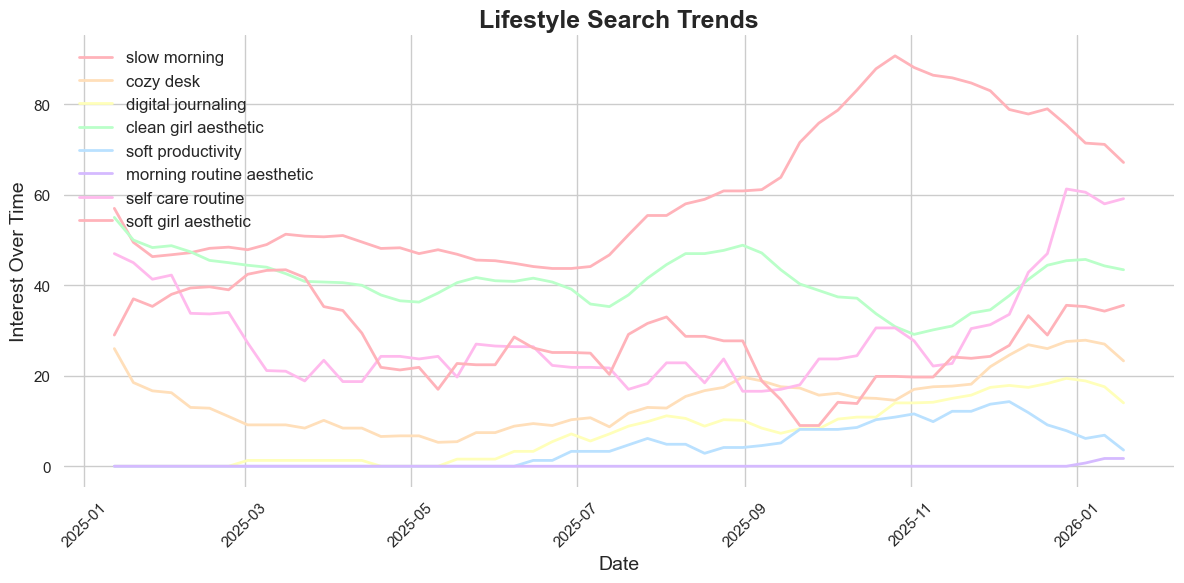

🎨 Saved chart to plots/lifestyle_trends.png


In [15]:



# -------------------------------
# 4️⃣ SMOOTH DATA
# -------------------------------
df_smooth = df.rolling(window=ROLLING_WINDOW, min_periods=1).mean()

# -------------------------------
# 5️⃣ PLOT TRENDS
# -------------------------------
plt.figure(figsize=(12, 6))

for i, column in enumerate(df_smooth.columns):
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], label=column, color=color, linewidth=2)

plt.title("Lifestyle Search Trends", fontsize=18, weight='bold')
plt.xlabel("Date", fontsize=14)
plt.ylabel("Interest Over Time", fontsize=14)
plt.xticks(rotation=45)
plt.legend(frameon=False, fontsize=12)
sns.despine(left=True, bottom=True)

# Save figure
output_file = f"{OUTPUT_DIR}/lifestyle_trends.png"
plt.tight_layout()
plt.savefig(output_file, dpi=300)
plt.show()
print(f"🎨 Saved chart to {output_file}")

# -------------------------------
# 6️⃣ OPTIONAL: EXPORT INDIVIDUAL CHARTS
# -------------------------------
for i, column in enumerate(df_smooth.columns):
    plt.figure(figsize=(8, 4))
    color = PASTEL_COLORS[i % len(PASTEL_COLORS)]
    plt.plot(df_smooth.index, df_smooth[column], color=color, linewidth=2)
    plt.title(column, fontsize=16, weight='bold')
    plt.xticks(rotation=45)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{column.replace(' ', '_')}.png", dpi=300)
    plt.close()
